# 02 - Scratch CNN baseline and ablations

**Owner:** Tejash (Part B)

This notebook trains our CNN from scratch. The baseline uses three convolution blocks. The optional ablation sweep changes one setting at a time: remove BatchNorm, or use two blocks instead of three.

The notebook uses the fixed split and the shared image loader. It chooses the best epoch with validation accuracy. Test scores are only calculated after a run is finished.

**Before running:** follow the README setup steps, download EuroSAT, and confirm that PyTorch can use the RTX 3050. The full ablation sweep takes much longer than the baseline.

In [1]:
from pathlib import Path
import json
import os
import sys

# Help CUDA reuse memory blocks on Windows. This does not change the model.
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')

# Make imports work whether Jupyter starts here or in the notebooks folder.
project_root = Path.cwd()
if not (project_root / 'src').is_dir():
    project_root = project_root.parent
os.chdir(project_root)
sys.path.insert(0, str(project_root))
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score

from src.dataset import get_loader
from src.models import build_scratch_cnn
from src.utils import FIGURES_DIR, METRICS_CSV, MODELS_DIR, get_device, set_seed

device = get_device()
print('Device:', device)
print('GPU:', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'not available')

Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [2]:
# These settings match the team plan.
BATCH_SIZE = 64
LEARNING_RATE = 0.001
MAX_EPOCHS = 20
SEEDS = [0, 1, 2]

# Change one setting for each ablation. Keep all other settings the same.
EXPERIMENTS = {
    'scratch_cnn': {'use_batchnorm': True, 'depth': 3, 'dropout': 0.0},
    'scratch_cnn_no_batchnorm': {'use_batchnorm': False, 'depth': 3, 'dropout': 0.0},
    'scratch_cnn_depth2': {'use_batchnorm': True, 'depth': 2, 'dropout': 0.0},
}

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
assert Path('data/splits.csv').is_file(), 'Missing fixed split: data/splits.csv'
assert (Path('data/eurosat/2750')).is_dir(), 'Download EuroSAT using the README setup steps.'

## Training and validation helpers

`score_model` measures one pass through a data loader. `train_one_model` updates weights using only training batches, checks validation accuracy after each epoch, and remembers the best weights. It does not look at test data.

In [3]:
def score_model(model, loader, loss_function):
    """Return average loss and accuracy for one pass through a data loader."""
    model.eval()
    total_loss = 0.0
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            scores = model(images)
            total_loss += loss_function(scores, labels).item() * len(labels)
            all_labels.extend(labels.cpu().tolist())
            all_predictions.extend(scores.argmax(dim=1).cpu().tolist())

    average_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_labels, all_predictions)
    return average_loss, accuracy


def train_one_model(model_name, options, seed, epochs=MAX_EPOCHS):
    """Train one setting and return the weights from its best validation epoch."""
    set_seed(seed)
    train_loader = get_loader(
        'train', seed=seed, augment=True, batch_size=BATCH_SIZE, num_workers=0
    )
    val_loader = get_loader('val', seed=seed, batch_size=BATCH_SIZE)

    model = build_scratch_cnn(**options).to(device)
    loss_function = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, foreach=False)
    history = {'train_loss': [], 'train_accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_accuracy = -1.0
    best_epoch = 0
    best_weights = None

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        correct = 0
        seen = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()
            scores = model(images)
            loss = loss_function(scores, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(labels)
            correct += (scores.argmax(dim=1) == labels).sum().item()
            seen += len(labels)

        train_loss = total_loss / seen
        train_accuracy = correct / seen
        val_loss, val_accuracy = score_model(model, val_loader, loss_function)
        history['train_loss'].append(train_loss)
        history['train_accuracy'].append(train_accuracy)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_accuracy)

        print(
            f'{model_name} | seed {seed} | epoch {epoch + 1:02d}/{epochs} | '
            f'train loss {train_loss:.4f}, train accuracy {train_accuracy:.3f} | '
            f'val loss {val_loss:.4f}, val accuracy {val_accuracy:.3f}'
        )

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_epoch = epoch + 1
            best_weights = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }

    model.load_state_dict(best_weights)
    print(f'Best validation accuracy: {best_accuracy:.3f} at epoch {best_epoch}')
    return model, history, best_epoch


## Lap 1: baseline learning curves

This first run uses seed 0 and checks learning with the validation set. It saves the curves and the best-validation weights. The weights go in the ignored `models/` folder, not in Git.

Loaded the completed local seed 0 baseline from its checkpoint and history.


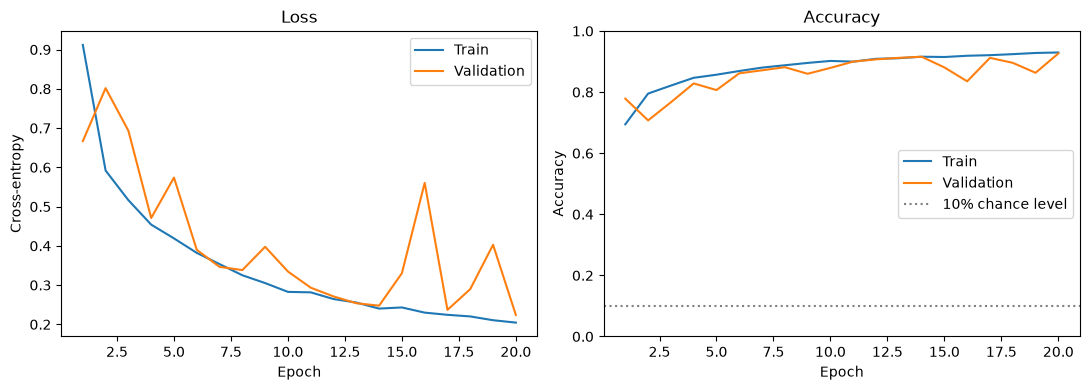

In [4]:
checkpoint_path = MODELS_DIR / 'scratch_cnn_baseline_seed0.pth'
history_path = FIGURES_DIR / 'scratch_cnn_seed0_history.json'

# Reuse a finished local run if its checkpoint and history are both present.
if checkpoint_path.is_file() and history_path.is_file():
    with open(history_path, encoding='utf-8') as file:
        baseline_history = json.load(file)
    baseline_model = build_scratch_cnn(**EXPERIMENTS['scratch_cnn']).to(device)
    baseline_model.load_state_dict(
        torch.load(checkpoint_path, map_location=device, weights_only=True)
    )
    baseline_best_epoch = max(
        range(len(baseline_history['val_accuracy'])),
        key=baseline_history['val_accuracy'].__getitem__,
    ) + 1
    print('Loaded the completed local seed 0 baseline from its checkpoint and history.')
else:
    start_time = time.perf_counter()
    baseline_model, baseline_history, baseline_best_epoch = train_one_model(
        'scratch_cnn', EXPERIMENTS['scratch_cnn'], seed=0
    )
    elapsed_minutes = (time.perf_counter() - start_time) / 60
    print(f'Baseline run took {elapsed_minutes:.1f} minutes')
    torch.save(baseline_model.state_dict(), checkpoint_path)
    with open(history_path, 'w', encoding='utf-8') as file:
        json.dump(baseline_history, file, indent=2)

epochs = range(1, len(baseline_history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, baseline_history['train_loss'], label='Train')
axes[0].plot(epochs, baseline_history['val_loss'], label='Validation')
axes[0].set(title='Loss', xlabel='Epoch', ylabel='Cross-entropy')
axes[0].legend()
axes[1].plot(epochs, baseline_history['train_accuracy'], label='Train')
axes[1].plot(epochs, baseline_history['val_accuracy'], label='Validation')
axes[1].axhline(0.10, color='gray', linestyle=':', label='10% chance level')
axes[1].set(title='Accuracy', xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1))
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'scratch_cnn_learning_curves.png', dpi=160)
plt.show()

### Reading the curves

The baseline is learning if validation accuracy rises clearly above 10%, the chance level for 10 balanced classes. If training accuracy keeps rising while validation accuracy stops rising or falls, the model may be overfitting. Use the curve that this run produces when writing the final interpretation.

## Lap 2: baseline and two ablations with three seeds

Run this cell after the full setup is ready. It trains each setting from scratch for seeds 0, 1 and 2, chooses the checkpoint by validation accuracy, and scores the test set once for each finished run. It appends results to `results/metrics.csv` and saves a mean ± standard deviation comparison plot.

**Shared trainer handoff:** `src/train.py` is still a TODO on this branch. This notebook currently uses its own helper so the experiment steps are visible. After Nitin adds `train()`, connect these ablation runs to that shared function before the final handoff, as the plan requests.

The test set is not used to choose the model or epoch.

Skip scratch_cnn, seed 0: test result is already saved.
Skip scratch_cnn, seed 1: test result is already saved.
Skip scratch_cnn, seed 2: test result is already saved.
Skip scratch_cnn_no_batchnorm, seed 0: test result is already saved.
Skip scratch_cnn_no_batchnorm, seed 1: test result is already saved.
Skip scratch_cnn_no_batchnorm, seed 2: test result is already saved.
Skip scratch_cnn_depth2, seed 0: test result is already saved.
Skip scratch_cnn_depth2, seed 1: test result is already saved.
Skip scratch_cnn_depth2, seed 2: test result is already saved.


accuracy            macro_f1          
                              mean       std      mean       std
model                                                           
scratch_cnn               0.927160  0.004465  0.924824  0.005080
scratch_cnn_depth2        0.853086  0.014332  0.841836  0.017844
scratch_cnn_no_batchnorm  0.889547  0.006345  0.884498  0.006419

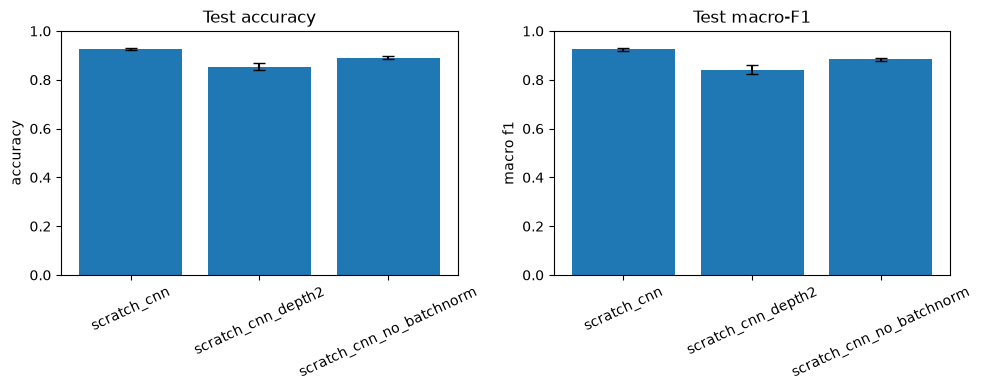

In [5]:
# Run the full Part B comparison. Completed runs are read from metrics.csv on reruns.
RUN_ABLATION_SWEEP = True

if RUN_ABLATION_SWEEP:
    all_results = (
        pd.read_csv(METRICS_CSV)
        if METRICS_CSV.exists()
        else pd.DataFrame(columns=['model', 'fraction', 'seed', 'accuracy', 'macro_f1'])
    )
    rows = []
    for model_name, options in EXPERIMENTS.items():
        for seed in SEEDS:
            already_done = (
                (all_results['model'] == model_name)
                & (all_results['fraction'] == 1.0)
                & (all_results['seed'] == seed)
            ).any()
            if already_done:
                print(f'Skip {model_name}, seed {seed}: test result is already saved.')
                continue

            if model_name == 'scratch_cnn' and seed == 0:
                # Seed 0 was trained above; reuse it and score its test split once.
                model = baseline_model
                best_epoch = baseline_best_epoch
            else:
                model, history, best_epoch = train_one_model(model_name, options, seed)
            test_loader = get_loader('test', seed=seed, batch_size=BATCH_SIZE)
            test_labels = []
            test_predictions = []
            model.eval()
            with torch.no_grad():
                for batch_number, (images, labels) in enumerate(test_loader, start=1):
                    scores = model(images.to(device))
                    test_labels.extend(labels.tolist())
                    test_predictions.extend(scores.argmax(dim=1).cpu().tolist())
                    if batch_number % 10 == 0:
                        print(f'test batches scored: {batch_number}')

            row = {
                'model': model_name,
                'fraction': 1.0,
                'seed': seed,
                'accuracy': accuracy_score(test_labels, test_predictions),
                'macro_f1': f1_score(test_labels, test_predictions, average='macro'),
            }
            rows.append(row)
            torch.save(
                model.state_dict(),
                MODELS_DIR / f'{model_name}_seed{seed}.pth',
            )
            same_run = (
                (all_results['model'] == model_name)
                & (all_results['fraction'] == 1.0)
                & (all_results['seed'] == seed)
            )
            all_results = all_results.loc[~same_run]
            all_results = pd.concat([all_results, pd.DataFrame([row])], ignore_index=True)
            all_results.to_csv(METRICS_CSV, index=False)
            print(f"Test result (best epoch {best_epoch}): {row}")

    comparison = all_results[
        all_results['model'].isin(EXPERIMENTS)
        & (all_results['fraction'] == 1.0)
        & all_results['seed'].isin(SEEDS)
    ]
    summary = comparison.groupby('model')[['accuracy', 'macro_f1']].agg(['mean', 'std'])
    display(summary)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for axis, metric, title in zip(
        axes, ['accuracy', 'macro_f1'], ['Test accuracy', 'Test macro-F1']
    ):
        grouped = comparison.groupby('model')[metric]
        means = grouped.mean()
        spreads = grouped.std().fillna(0)
        axis.bar(means.index, means.values, yerr=spreads.values, capsize=4)
        axis.set(title=title, ylabel=metric.replace('_', ' '), ylim=(0, 1))
        axis.tick_params(axis='x', rotation=25)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / 'scratch_cnn_ablation_comparison.png', dpi=160)
    plt.show()
else:
    print('Ablation sweep not run. Set RUN_ABLATION_SWEEP = True when ready.')

## Discussion to complete after the sweep

Compare each ablation with the baseline using the three-seed table. Say whether the mean changed, how large the seed-to-seed standard deviation was, and whether the change is consistent across seeds. Do not claim that an ablation helped or hurt until the actual results are available.